[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/main/notebooks/2_compute_g.ipynb)

# Compute G(x)

* **Author**: laquitainesteeve@gmail.com

* **Goal**: Train the diffusion model that the multi-scale Fisher metric G(x) needs, with responses predicted by the encoder of notebook 1, then compute and plot G(x) and J(x). Any encoder that follows the encoder contract works.

* **Requirements**: notebook 1 run once, TinyImageNet (downloaded on the first run), `diffusers`, and preferably a GPU.

* **Time**: about 2 min on a GPU. The model is tiny, so G(x) is rough; notebook 3 shows the quality of the paper's checkpoints.

## 1. Setup

### 1.1. Install package

On Google Colab, install `multigeom` and `diffusers`; elsewhere this does nothing.

time: <1 sec

In [1]:
%%time

# on Google Colab install the package from PyPI, without its dependencies: Colab already
# has torch, numpy, scipy and matplotlib, and reinstalling torch is slow and can break
# the GPU runtime (nothing to do on your own machine)
import sys

if "google.colab" in sys.modules:
    %pip install -q --no-deps --pre multigeom
    %pip install -q "diffusers>=0.30,<0.38"     # the diffusion model of this notebook

CPU times: user 2 μs, sys: 0 ns, total: 2 μs
Wall time: 4.05 μs


### 1.2. Imports and parameters

Work from the repository root, import the packages, set the parameters and pick the device.

time: 3 secs

In [2]:
%%time

# move to the repository root (the folder containing environment.yml): data/ and runs/
# are read from there
import os
from pathlib import Path

root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent

if (root / "environment.yml").exists():
    os.chdir(root)

print("working folder:", Path.cwd())

# libraries and the package
import time

import matplotlib.pyplot as plt
import numpy as np
import torch

import multigeom
from multigeom import compute_fisher, compute_g, load_encoder, subspace_alignment
from multigeom.config import load_config
from multigeom.datasets import GaborTeacher, TinyImageNetDataset, download_tinyimagenet
from multigeom.diffusion import DiffusionConfig
from multigeom.diffusion.model import build_diffusion_model, build_scheduler
from multigeom.diffusion.responses import precompute_responses
from multigeom.diffusion.train import train_diffusion
from multigeom.utils import make_generator

# device and random seed
device = "cuda" if torch.cuda.is_available() else "cpu"
dev = torch.device(device)
torch.manual_seed(0)

# parameters
SAVE_DIR = Path("runs/getting_started")

# TinyImageNet images to train the diffusion model on (200 classes)
IMAGES_PER_CLASS = 100
EPOCHS = 5
N_MC = 50  # Monte-Carlo samples of the G(x) estimator (the paper uses 200)

# spacing of the diffusion times in the integral over scales (the paper uses 40)
TIMESTEP_STEP = 80
N_COMPARE = 10  # test images for the comparison with the ground truth
if device == "cpu":  # a few minutes on a CPU
    IMAGES_PER_CLASS, EPOCHS, N_MC, TIMESTEP_STEP, N_COMPARE = 10, 1, 10, 160, 3

print("multigeom", multigeom.__version__, "| device:", device)

working folder: /home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials
multigeom 0.1.0.dev2 | device: cuda
CPU times: user 4.22 s, sys: 363 ms, total: 4.58 s
Wall time: 3.3 s


### 1.3. Custom functions

`show` draws one eigenvector as an image.

time: <1 sec

In [3]:
%%time


def show(ax, vec):
    """Draw one eigenvector as a 64 x 64 image (red positive, blue negative)."""
    v = vec.reshape(64, 64).cpu()
    m = v.abs().quantile(0.99)
    ax.imshow(v, cmap="RdBu_r", vmin=-m, vmax=m)
    ax.axis("off")

CPU times: user 3 μs, sys: 0 ns, total: 3 μs
Wall time: 6.44 μs


## 2. Load the encoder and predict responses to many images

We load the encoder saved by notebook 1 (or `load_encoder("inception", area="V1")`). The diffusion model is trained on TinyImageNet images with the responses **predicted by the encoder**.

time: 4 secs

In [4]:
%%time

# 1. the encoder saved by notebook 1
encoder_path = SAVE_DIR / "encoder.pt"
if not encoder_path.exists():
    raise FileNotFoundError(
        f"{encoder_path} not found: run notebook 1 first, or load an encoder of the "
        "paper: "
        "load_encoder('inception', area='V1')"
    )

encoder = load_encoder(encoder_path, device=device)
print(encoder.summary())

# 2. TinyImageNet training images
download_tinyimagenet()  # 240 MB, downloaded the first time only (about 1 min)
dataset = TinyImageNetDataset("train", images_per_class=IMAGES_PER_CLASS)

# [N, 1, 64, 64] in [-1, 1]
images = torch.stack([dataset[i] for i in range(len(dataset))])

# 3. responses predicted by the encoder: the conditioning of the diffusion model
t0 = time.time()
responses = precompute_responses(encoder, images, batch_size=512, device=device)
print(
    f"{len(images)} images -> responses {tuple(responses.shape)} in "
    f"{time.time() - t0:.1f} s; "
    f"mean {responses.mean():.2f}, std {responses.std():.2f}"
)

NeuralEncoder: backbone SmallCNNBackbone (out [C=64, 16, 16]), readout GaussianReadout, 50 neurons, 59,976 trainable / 59,976 parameters
20000 images -> responses (20000, 50) in 0.9 s; mean 1.29, std 0.64
CPU times: user 13.3 s, sys: 555 ms, total: 13.8 s
Wall time: 4.94 s


## 3. Set up the diffusion model

`DiffusionConfig.for_encoder(encoder)` sets the conditioning width to the number of neurons. We shrink the model so that it trains in about a minute.

<details><summary>Details</summary>

| | paper | here |
|---|---|---|
| UNet channels, layers per block | (64, 128, 256, 512), 2 | (32, 64, 128, 128), 1 |
| conditioning width | 256 | 64 |
| training images, epochs, batch | 100,000, 200, 128 | `IMAGES_PER_CLASS` x 200, `EPOCHS`, 64 |

The noise sigma of the observation model (0.22) must be the same in the diffusion model and in the estimator; both read it from the packaged configuration.

</details>

time: <1 sec

In [5]:
%%time

# conditioning input width = number of neurons
cfg = DiffusionConfig.for_encoder(encoder)

# shrink the model and the recipe so that it trains in about a minute
cfg.unet.block_channels = [32, 64, 128, 128]
cfg.unet.layers_per_block = 1
cfg.unet.cross_attention_dim = 64
cfg.conditioning.mlp_layers = [encoder.n_neurons, 64, 64, 64]
cfg.train.epochs, cfg.train.batch_size, cfg.train.lr, cfg.train.warmup_steps = (
    EPOCHS,
    64,
    3e-4,
    100,
)

# build it once, to count its parameters
model = build_diffusion_model(cfg)
print(
    f"diffusion model: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} M "
    "parameters "
    f"(the paper's: 68 M) | noise sigma {cfg.conditioning.observation_noise_sigma}"
)

del model

diffusion model: 5.5 M parameters (the paper's: 68 M) | noise sigma 0.22
CPU times: user 86 ms, sys: 4.33 ms, total: 90.3 ms
Wall time: 39.8 ms


## 4. Train the diffusion model

`train_diffusion(cfg, images, responses, out_dir)` writes `final_model.pt` after every epoch and resumes an interrupted run with `resume=True`.

<details><summary>Details</summary>

It trains the model to predict the noise added to the images, given the noisy responses, with classifier-free guidance dropout so that the same network also gives the unconditional prediction.

</details>

time: 2 min

trained for 5 epochs in 99 s | loss 0.151 -> 0.070


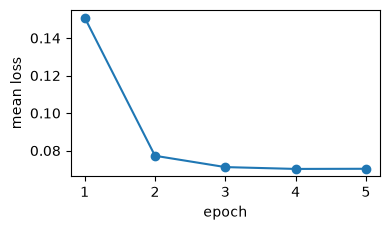

CPU times: user 8min 2s, sys: 1.18 s, total: 8min 4s
Wall time: 1min 39s


In [6]:
%%time

# train: the model learns to predict the noise added to the images, given the responses
t0 = time.time()
history = train_diffusion(
    cfg,
    images,
    responses,
    SAVE_DIR / "diffusion",
    device=device,
    num_workers=0,
    save_every=1000,
    log=None,
)

print(
    f"trained for {EPOCHS} epochs in {time.time() - t0:.0f} s | loss "
    f"{history['loss'][0]:.3f} -> {history['loss'][-1]:.3f}"
)

# training loss
plt.figure(figsize=(4, 2.4))
plt.plot(history["epoch"], history["loss"], "o-")
plt.xlabel("epoch")
plt.ylabel("mean loss")
plt.tight_layout()
plt.show()

## 5. Compute G(x) and J(x)

For test images the diffusion model never saw, `compute_g` gives the leading eigenvectors of the multi-scale Fisher metric G(x), and `compute_fisher` those of J(x).

<details><summary>Details</summary>

`compute_g` is the conditional-pair estimator of the paper: Monte-Carlo samples at every diffusion time, noise-prediction differences for two responses sampled around the encoder's prediction, then an SVD. `compute_fisher` is closed form from the encoder's Jacobian. Both take the image, the encoder and settings; `compute_g` also takes the diffusion model and its noise schedule.

</details>

time: 2 min

In [7]:
%%time

# 1. the trained diffusion model and its noise schedule
unet = build_diffusion_model(cfg).to(dev)
unet.load_state_dict(
    torch.load(
        SAVE_DIR / "diffusion" / "final_model.pt", map_location=dev, weights_only=False
    )["model_state_dict"]
)

unet.eval()
alphas_cumprod = build_scheduler(cfg).alphas_cumprod.to(dev)

# 2. settings of the estimator
est = load_config("estimator")  # the packaged settings of the estimator
est.monte_carlo.n_samples = N_MC
est.monte_carlo.timestep_grid.step = TIMESTEP_STEP
est.top_k = 20
sigma = float(est.monte_carlo.observation_noise_sigma)

# 3. G(x) and J(x) for the test images
# TinyImageNet validation images
test_images = torch.stack([TinyImageNetDataset("val")[i] for i in range(N_COMPARE)])

G, J = [], []
t0 = time.time()
for i, x in enumerate(test_images):
    x = x.unsqueeze(0).to(dev)
    G.append(
        compute_g(
            image=x,
            encoder=encoder,
            unet=unet,
            alphas_cumprod=alphas_cumprod,
            cfg=est,
            device=dev,
            generator=make_generator(int(est.seed) + i, dev),
        )
    )
    J.append(
        compute_fisher(image=x, encoder=encoder, sigma=sigma, top_k=20, device=dev)
    )

print(f"G(x) and J(x) for {len(test_images)} images in {time.time() - t0:.1f} s")
print(
    "leading eigenvalues of G(x), image 0:",
    [f"{v:.3g}" for v in G[0].eigenvalues[:4].tolist()],
)

print(
    "leading eigenvalues of J(x), image 0:",
    [f"{v:.3g}" for v in J[0].eigenvalues[:4].tolist()],
)

<timed exec>:39: UserWarning: R9: responses have std 0.0705 over random test images, while the noise sigma is 0.22; the pipeline expects responses of order 1 (for example z-scored). Rescale the model's output or set sigma accordingly. (Random noise images only approximate natural-image statistics.)


G(x) and J(x) for 10 images in 116.1 s
leading eigenvalues of G(x), image 0: ['0.697', '0.121', '0.0839', '0.0639']
leading eigenvalues of J(x), image 0: ['88.7', '50.4', '39.3', '32.1']
CPU times: user 31min 4s, sys: 401 ms, total: 31min 4s
Wall time: 1min 57s


## 6. Plot

The leading eigenvectors of each metric (red positive, blue negative; the sign is arbitrary), as in the paper's Fig. 3E-F.

time: <1 sec

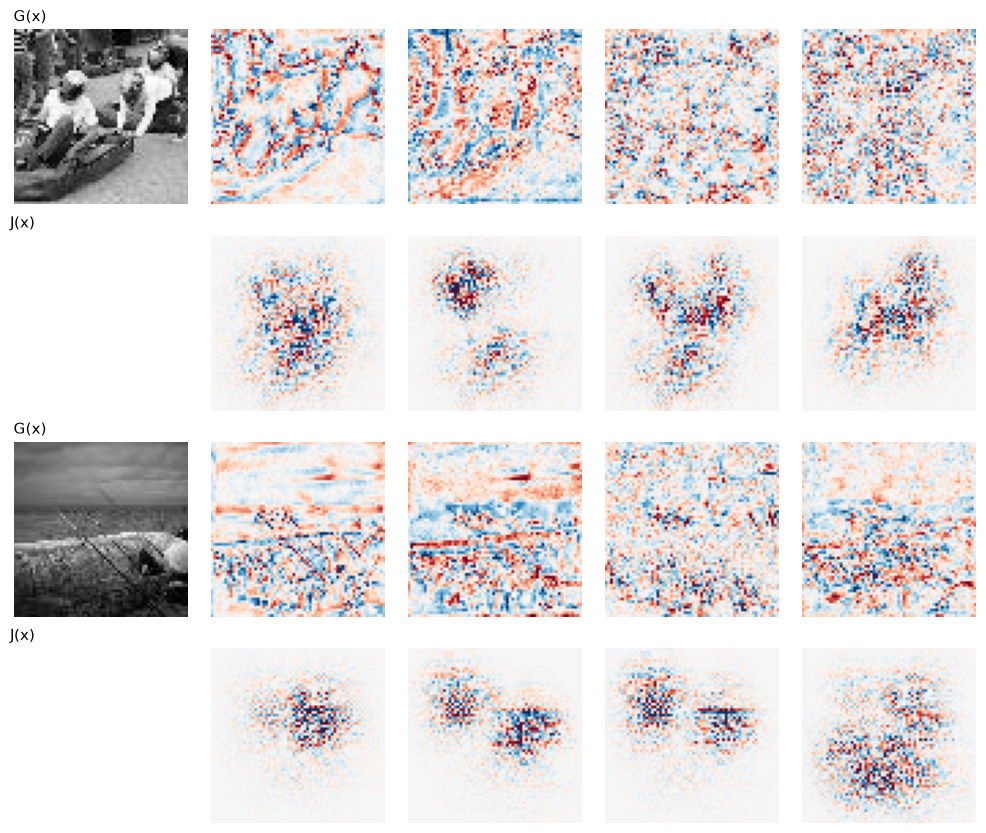

CPU times: user 270 ms, sys: 1 μs, total: 270 ms
Wall time: 259 ms


In [8]:
%%time

# image, leading eigenvectors of G(x) (first row) and of J(x) (second row) of the first
# test images
n_show = min(2, len(test_images))
fig, axes = plt.subplots(2 * n_show, 5, figsize=(10, 4.2 * n_show))
for i in range(n_show):
    for r, (label, out) in enumerate([("G(x)", G[i]), ("J(x)", J[i])]):
        row = 2 * i + r
        axes[row, 0].imshow(
            test_images[i, 0], cmap="gray", vmin=-1, vmax=1
        ) if r == 0 else None
        axes[row, 0].axis("off")
        axes[row, 0].set_title(label, loc="left", fontsize=11)
        for k in range(4):
            show(axes[row, k + 1], out.eigenvectors[k])

plt.tight_layout()
plt.show()

## 7. Compare with the ground truth

The subspace alignment $\mathcal{A}_k$ is 1 when the top-k eigenvectors of two metrics span the same subspace (chance: k / 4096). We compare the encoder's G(x) and J(x) with the teacher's J(x), averaged over test images.

<details><summary>Details</summary>

The diffusion model here is tiny and briefly trained, there is one fitted encoder, and the teacher's own G(x) would need a diffusion model trained on the teacher's responses. The numbers say how close this small experiment gets, nothing more.

</details>

time: <1 sec

In [9]:
%%time

# 1. the ground-truth teacher saved by notebook 1, and its J(x) at the test images
saved = torch.load(SAVE_DIR / "teacher.pt", weights_only=False)
teacher = GaborTeacher(saved["n_neurons"], seed=saved["seed"]).to(dev)
teacher.load_state_dict(saved["state_dict"])
J_true = [
    compute_fisher(
        image=x.unsqueeze(0).to(dev), encoder=teacher, sigma=sigma, top_k=20, device=dev
    )
    for x in test_images
]

# 2. subspace alignment with the ground truth, for a few values of k
print(
    f"subspace alignment with the ground-truth J(x), mean over {len(test_images)} "
    "images (chance = k / 4096):"
)

print(f"{'k':>3s} {'chance':>8s} {'J of the encoder':>18s} {'G of the encoder':>18s}")
for k in (1, 5, 10):
    a_j = np.mean(
        [
            subspace_alignment(j.eigenvectors.cpu(), t.eigenvectors.cpu(), k)
            for j, t in zip(J, J_true)
        ]
    )
    a_g = np.mean(
        [
            subspace_alignment(g.eigenvectors.cpu(), t.eigenvectors.cpu(), k)
            for g, t in zip(G, J_true)
        ]
    )
    print(f"{k:3d} {k / 4096:8.4f} {a_j:18.3f} {a_g:18.3f}")

subspace alignment with the ground-truth J(x), mean over 10 images (chance = k / 4096):
  k   chance   J of the encoder   G of the encoder
  1   0.0002              0.009              0.009
  5   0.0012              0.011              0.011
 10   0.0024              0.016              0.014
CPU times: user 3.24 s, sys: 9.02 ms, total: 3.24 s
Wall time: 391 ms


## 8. Recap and next steps

| To do | Call |
|---|---|
| responses of an encoder to many images | `precompute_responses(encoder, images)` |
| diffusion configuration for an encoder | `DiffusionConfig.for_encoder(encoder)` |
| train the diffusion model | `train_diffusion(cfg, images, responses, out_dir)` |
| multi-scale Fisher metric G(x) | `multigeom.compute_g(image=x, encoder=encoder, unet=unet, alphas_cumprod=..., cfg=est, device=...)` |
| Fisher information J(x) | `multigeom.compute_fisher(image=x, encoder=encoder, sigma=0.22)` |
| similarity of two sets of eigenvectors | `multigeom.subspace_alignment(eigvecs_a, eigvecs_b, k)` |

The same steps, for many images and several encoders, are the command-line stages of the pipeline (`multigeom train-diffusion`, `multigeom compute-g`, `multigeom align`). **Next**: notebooks 3 to 6 reproduce the figures of the paper from its trained checkpoints.